In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/concrete/compressive/"
    "Concrete_Data.xls"
)

df = pd.read_excel(url)

df.columns = [
    "cement",
    "slag",
    "fly_ash",
    "water",
    "superplasticizer",
    "coarse_aggregate",
    "fine_aggregate",
    "age",
    "strength"
]

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Dataset shape: (1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
%pip install xlrd

In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_aggregate  1030 non-null   float64
 6   fine_aggregate    1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing values:
cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_aggregate    0
fine_aggregate      0
age                 0
strength            0
dtype: int64

Duplicate rows: 25

Statistical summary:


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [5]:
# Replace infinite values with missing values
df = df.replace([np.inf, -np.inf], np.nan)

# Remove rows without the target value
df = df.dropna(subset=["strength"])

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Cleaned dataset shape: (1005, 9)

Missing values after cleaning:
cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_aggregate    0
fine_aggregate      0
age                 0
strength            0
dtype: int64


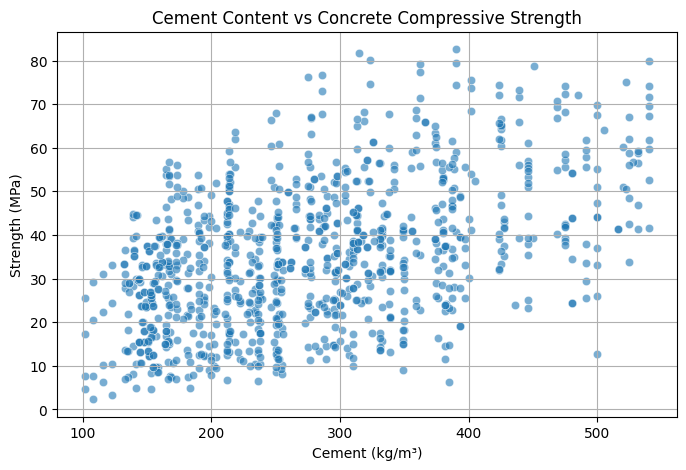

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="cement",
    y="strength",
    alpha=0.6
)

plt.title("Cement Content vs Concrete Compressive Strength")
plt.xlabel("Cement (kg/m³)")
plt.ylabel("Strength (MPa)")
plt.grid(True)
plt.show()

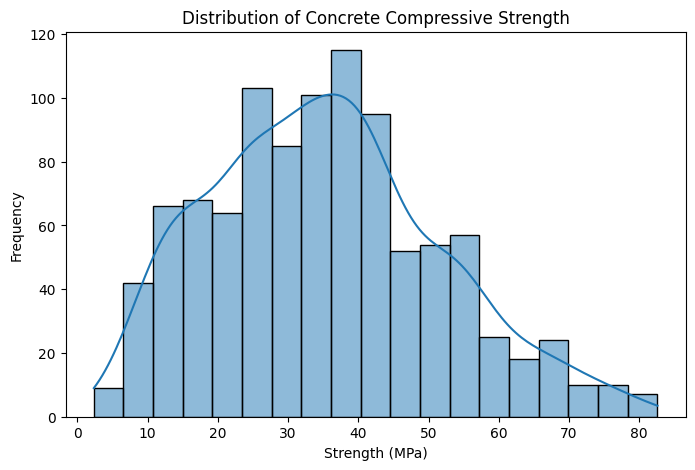

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="strength", kde=True)

plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Strength (MPa)")
plt.ylabel("Frequency")
plt.show()

In [8]:
X = df.drop(columns=["strength"])
y = df["strength"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1005, 8)
Target shape: (1005,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 804
Testing samples: 201


In [10]:
def evaluate_model(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

print("Evaluation function created!")

Evaluation function created!


In [11]:
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

train_pred = linear_model.predict(X_train)
test_pred = linear_model.predict(X_test)

print("Linear Regression — Training Results")
print(evaluate_model(y_train, train_pred))

print("\nLinear Regression — Testing Results")
print(evaluate_model(y_test, test_pred))

Linear Regression — Training Results
{'MSE': 100.0505469187892, 'RMSE': np.float64(10.002527026646277), 'R2': 0.6098078356006248}

Linear Regression — Testing Results
{'MSE': 125.26533827672503, 'RMSE': np.float64(11.192199885488332), 'R2': 0.5801089019953829}


In [12]:
degrees = [1, 2, 3, 4, 5]

polynomial_results = []
polynomial_models = {}

for degree in degrees:

    poly_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])

    poly_model.fit(X_train, y_train)

    train_pred = poly_model.predict(X_train)
    test_pred = poly_model.predict(X_test)

    train_metrics = evaluate_model(y_train, train_pred)
    test_metrics = evaluate_model(y_test, test_pred)

    polynomial_results.append({
        "Model": f"Polynomial Degree {degree}",
        "Degree": degree,
        "Train MSE": train_metrics["MSE"],
        "Test MSE": test_metrics["MSE"],
        "Train RMSE": train_metrics["RMSE"],
        "Test RMSE": test_metrics["RMSE"],
        "Train R2": train_metrics["R2"],
        "Test R2": test_metrics["R2"]
    })

    polynomial_models[degree] = poly_model

polynomial_df = pd.DataFrame(polynomial_results)

display(polynomial_df.round(4))

,Model,Degree,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Polynomial Degree 1,1,100.0505,1.252653e+02,10.0025,11.1922,0.6098,5.801000e-01
1,Polynomial Degree 2,2,48.8387,6.903640e+01,6.9885,8.3088,0.8095,7.686000e-01
2,Polynomial Degree 3,3,19.3181,3.538370e+01,4.3952,5.9484,0.9247,8.814000e-01
3,Polynomial Degree 4,4,4.6011,1.020136e+04,2.1450,101.0018,0.9821,-3.319510e+01
4,Polynomial Degree 5,5,1.5328,4.582151e+09,1.2381,67691.5857,0.9940,-1.535943e+07


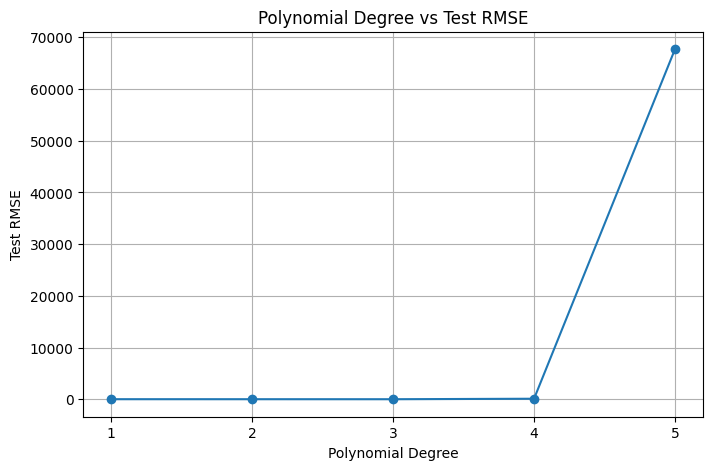

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    polynomial_df["Degree"],
    polynomial_df["Test RMSE"],
    marker="o"
)

plt.title("Polynomial Degree vs Test RMSE")
plt.xlabel("Polynomial Degree")
plt.ylabel("Test RMSE")
plt.xticks(degrees)
plt.grid(True)
plt.show()

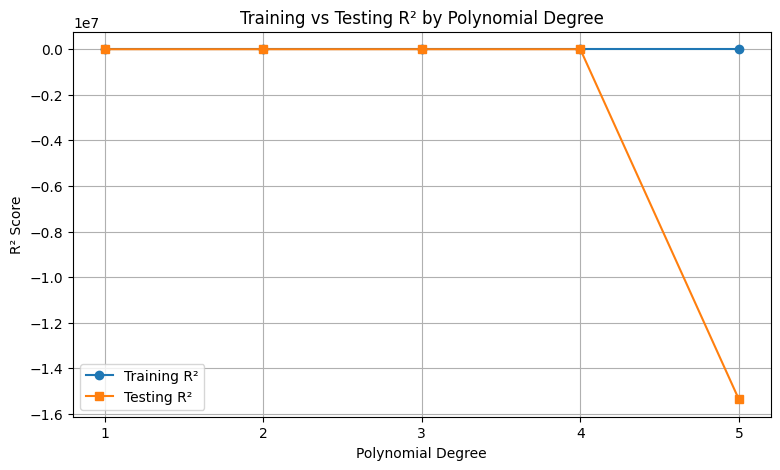

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    polynomial_df["Degree"],
    polynomial_df["Train R2"],
    marker="o",
    label="Training R²"
)

plt.plot(
    polynomial_df["Degree"],
    polynomial_df["Test R2"],
    marker="s",
    label="Testing R²"
)

plt.title("Training vs Testing R² by Polynomial Degree")
plt.xlabel("Polynomial Degree")
plt.ylabel("R² Score")
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

In [15]:
regularization_results = []
regularized_models = {}

estimators = [
    ("Ridge", Ridge(alpha=10.0)),
    ("Lasso", Lasso(alpha=0.1, max_iter=20000))
]

for name, estimator in estimators:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(
            degree=3,
            include_bias=False
        )),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_metrics = evaluate_model(y_train, train_pred)
    test_metrics = evaluate_model(y_test, test_pred)

    regularization_results.append({
        "Model": name,
        "Train MSE": train_metrics["MSE"],
        "Test MSE": test_metrics["MSE"],
        "Train RMSE": train_metrics["RMSE"],
        "Test RMSE": test_metrics["RMSE"],
        "Train R2": train_metrics["R2"],
        "Test R2": test_metrics["R2"]
    })

    regularized_models[name] = model

regularization_df = pd.DataFrame(regularization_results)

display(regularization_df.round(4))

,Model,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Ridge,38.7600,51.6588,6.2258,7.1874,0.8488,0.8268
1,Lasso,46.8729,60.7919,6.8464,7.7969,0.8172,0.7962


In [16]:
# Calculate baseline metrics
linear_train = evaluate_model(
    y_train, linear_model.predict(X_train)
)
linear_test = evaluate_model(
    y_test, linear_model.predict(X_test)
)

linear_df = pd.DataFrame([{
    "Model": "Linear Regression",
    "Train MSE": linear_train["MSE"],
    "Test MSE": linear_test["MSE"],
    "Train RMSE": linear_train["RMSE"],
    "Test RMSE": linear_test["RMSE"],
    "Train R2": linear_train["R2"],
    "Test R2": linear_test["R2"]
}])

comparison_df = pd.concat(
    [
        linear_df,
        polynomial_df.drop(columns=["Degree"]),
        regularization_df
    ],
    ignore_index=True
)

display(comparison_df.round(4))

,Model,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,100.0505,1.252653e+02,10.0025,11.1922,0.6098,5.801000e-01
1,Polynomial Degree 1,100.0505,1.252653e+02,10.0025,11.1922,0.6098,5.801000e-01
2,Polynomial Degree 2,48.8387,6.903640e+01,6.9885,8.3088,0.8095,7.686000e-01
3,Polynomial Degree 3,19.3181,3.538370e+01,4.3952,5.9484,0.9247,8.814000e-01
4,Polynomial Degree 4,4.6011,1.020136e+04,2.1450,101.0018,0.9821,-3.319510e+01
5,Polynomial Degree 5,1.5328,4.582151e+09,1.2381,67691.5857,0.9940,-1.535943e+07
6,Ridge,38.7600,5.165880e+01,6.2258,7.1874,0.8488,8.268000e-01
7,Lasso,46.8729,6.079190e+01,6.8464,7.7969,0.8172,7.962000e-01


In [17]:
best_row = comparison_df.loc[
    comparison_df["Test RMSE"].idxmin()
]

print("Best model based on testing RMSE:")
display(best_row.to_frame().T)

Best model based on testing RMSE:


,Model,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
3,Polynomial Degree 3,19.318074,35.3837,4.395233,5.94842,0.92466,0.881393


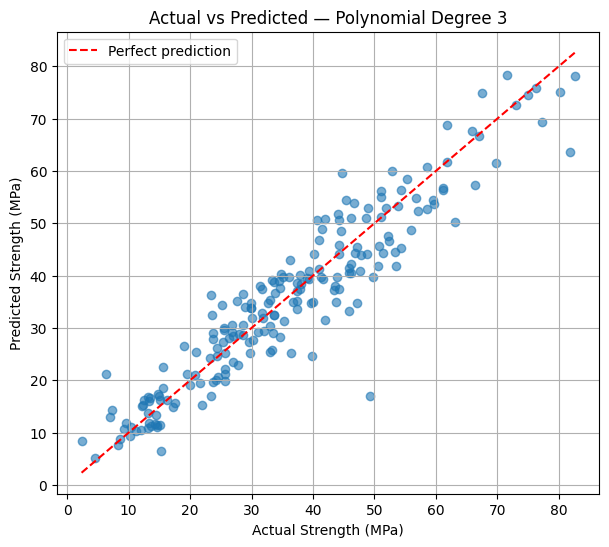

In [18]:
best_degree = int(
    polynomial_df.loc[
        polynomial_df["Test RMSE"].idxmin(),
        "Degree"
    ]
)

best_poly_model = polynomial_models[best_degree]

y_pred = best_poly_model.predict(X_test)

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title(f"Actual vs Predicted — Polynomial Degree {best_degree}")
plt.legend()
plt.grid(True)
plt.show()